In [ ]:
# load packages
import napari
import numpy as np
import dask.array as da
from napari.utils.notebook_display import nbscreenshot
from rich.pretty import pprint
from napari_ome_zarr import napari_get_reader
from ultrack import MainConfig, load_config, track, to_tracks_layer, tracks_to_zarr
from ultrack.imgproc import robust_invert, detect_foreground
from ultrack.utils.array import array_apply, create_zarr
from functions import pink_fluor, PINK, PLUM, segment_frame


Root group {'multiscales': [{'axes': [{'name': 't', 'type': 'time'}, {'name': 'c', 'type': 'channel'}, {'name': 'z', 'type': 'space', 'unit': 'micrometer'}, {'name': 'y', 'type': 'space', 'unit': 'micrometer'}, {'name': 'x', 'type': 'space', 'unit': 'micrometer'}], 'datasets': [{'coordinateTransformations': [{'scale': [1.0, 1.0, 1.24, 0.439, 0.439], 'type': 'scale'}], 'path': '0'}, {'coordinateTransformations': [{'scale': [1.0, 1.0, 2.48, 0.878, 0.878], 'type': 'scale'}], 'path': '1'}, {'coordinateTransformations': [{'scale': [1.0, 1.0, 4.96, 1.756, 1.756], 'type': 'scale'}], 'path': '2'}], 'metadata': {'method': 'cucim.skimage.transform.downscale_local_mean', 'version': '22.12.00'}, 'type': 'local_mean', 'version': '0.4'}], 'omero': {'channels': [{'active': True, 'coefficient': 1, 'color': 'FFFFFF', 'family': 'linear', 'inverted': False, 'label': 'fused', 'window': {'end': 1500, 'max': 65535, 'min': 0, 'start': 0}}], 'id': 1, 'name': '/hpc/projects/gpfsMicro/Microscopy1/_pisces/nmp_an

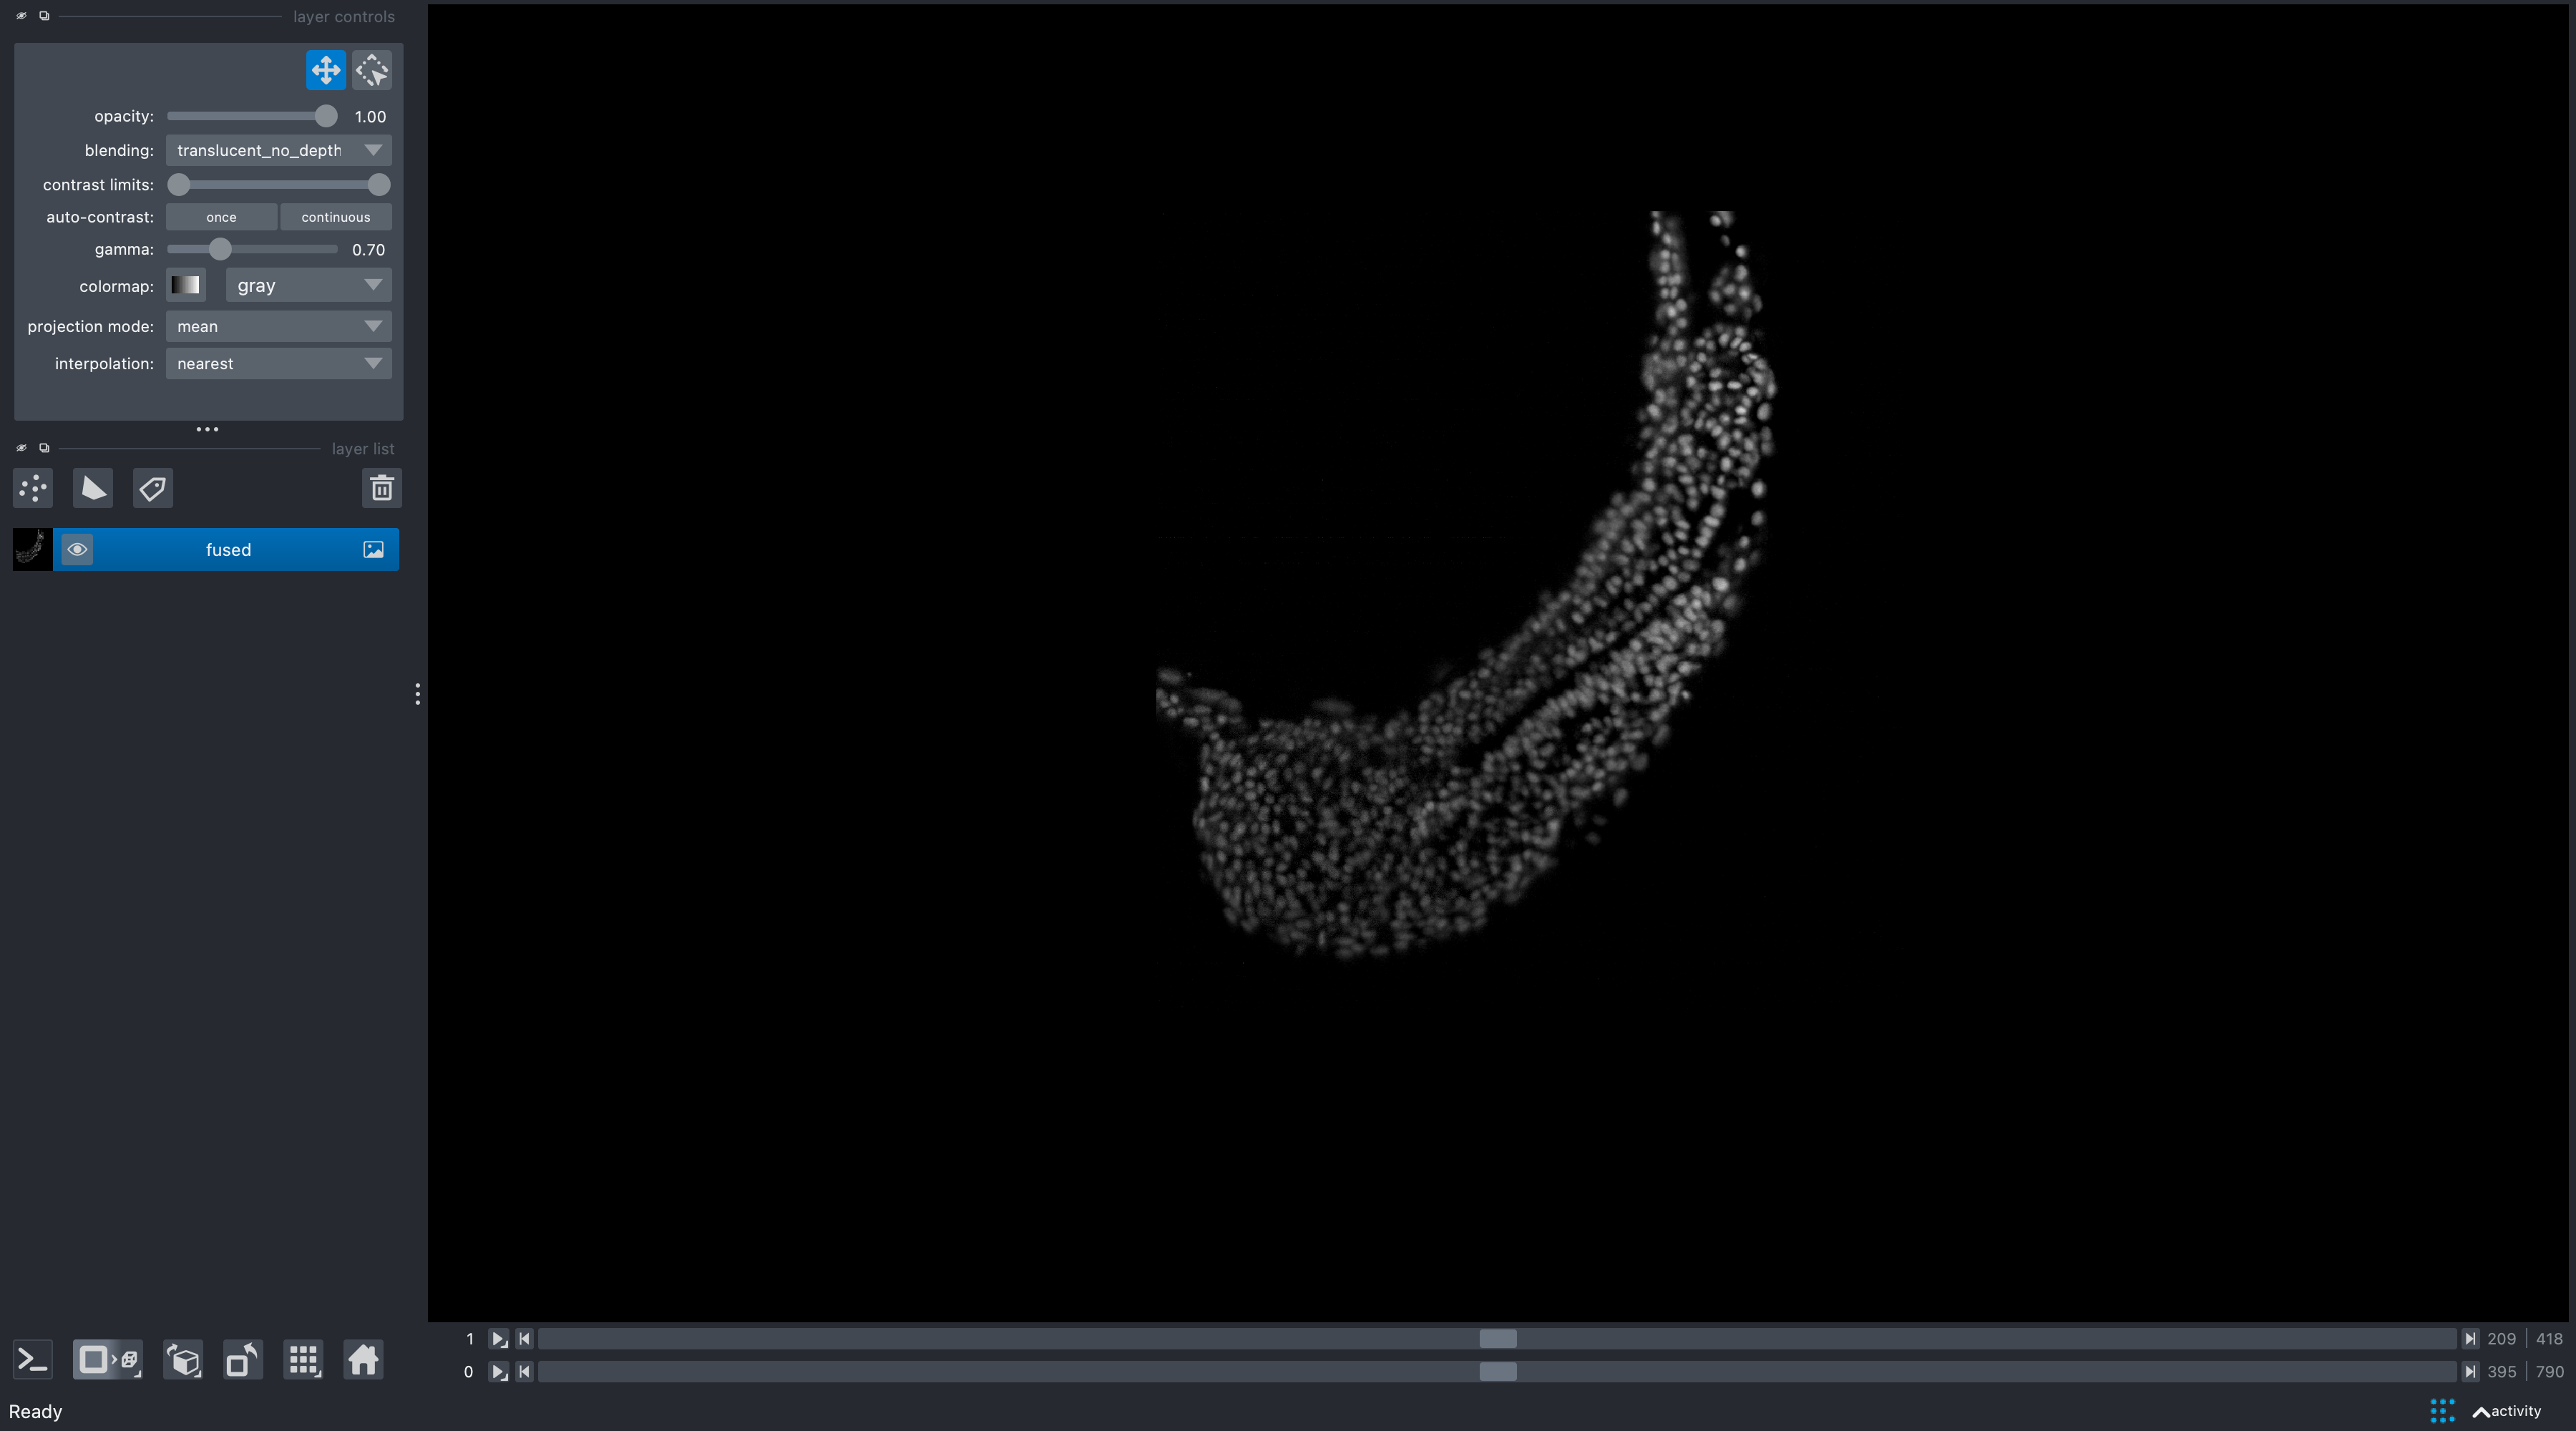

In [4]:
viewer = napari.Viewer()
viewer.window.resize(1800, 1000)

im_layer, = viewer.open(
    "http://public.czbiohub.org/royerlab/zebrahub/imaging/single-objective/ZSNS001_tail.ome.zarr/",
    plugin="napari-ome-zarr",
    rendering="attenuated_mip",
    gamma=0.7,
    contrast_limits=(0, 500),
)

nbscreenshot(viewer)

In [7]:
voxel_size = im_layer.scale[1:]  # (z, y, x) pixel size
start_idx = 400  # starting frame
viewer.dims.set_point(0, start_idx + 5)

image = im_layer.data[0]
image = image[start_idx:(start_idx + 10)]  # processing only a subset of time points
image.shape

(10, 420, 1217, 1091)

In [8]:
detection = create_zarr(image.shape, bool, store_or_path="detection.zarr", overwrite=True)
array_apply(
    image,
    out_array=detection,
    func=detect_foreground,
    sigma=25.0,
    voxel_size=voxel_size,
)

viewer.add_labels(
    detection,
    visible=True,
    translate=(start_idx, 0, 0, 0),
    scale=voxel_size,
).contour = 2

nbscreenshot(viewer)

Applying detect_foreground ...:   0%|          | 0/10 [01:01<?, ?it/s]


KeyboardInterrupt: 

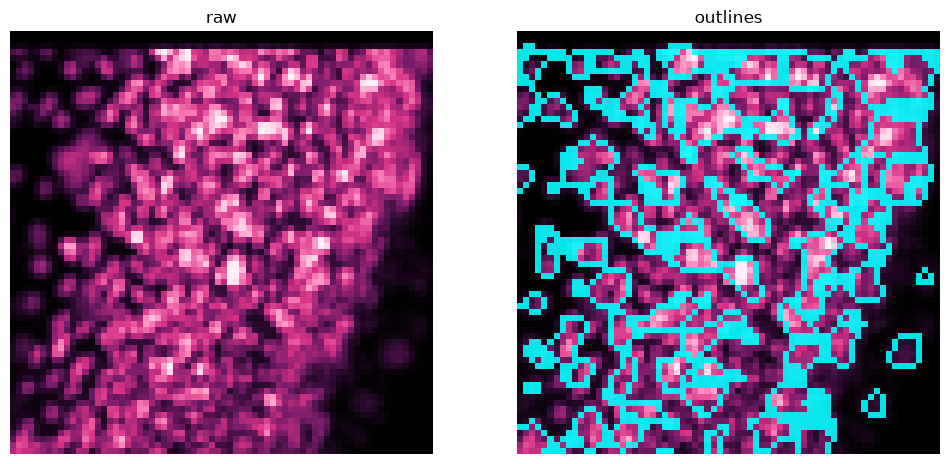

In [4]:
# pick a bright 70x70 patch fully inside the tissue, so we can zoom in
size = 70
best = None
for y in range(0, f.shape[0] - size + 1, 10):
    for x in range(0, f.shape[1] - size + 1, 10):
        if inside[y:y+size, x:x+size].mean() > 0.9:
            m = f[y:y+size, x:x+size].mean()
            if best is None or m > best[0]:
                best = (m, y, x)
_, y, x = best
ys, xs = slice(y, y + size), slice(x, x + size)

# outlines on the image, without a function
edges = segmentation.find_boundaries(labels, mode="inner")
outline = np.zeros(f.shape + (4,))
outline[edges] = (0, 1, 1, 0.9)                  # cyan outlines

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(f[ys, xs], cmap=pink_fluor, vmin=0, vmax=1.2)
axes[0].set_title("raw")
axes[1].imshow(f[ys, xs], cmap=pink_fluor, vmin=0, vmax=1.2)
axes[1].imshow(outline[ys, xs])
axes[1].set_title("outlines")
for ax in axes: ax.axis("off")
plt.show()

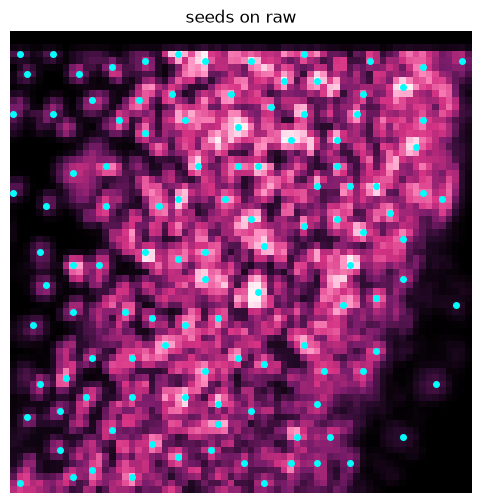

In [16]:
f = norm[0]
_, seeds = segment_frame(f, inside, **params)
in_patch = ((seeds[:, 0] >= ys.start) & (seeds[:, 0] < ys.stop) &
            (seeds[:, 1] >= xs.start) & (seeds[:, 1] < xs.stop))

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(f[ys, xs], cmap=pink_fluor, vmin=0, vmax=1.2)
ax.plot(seeds[in_patch, 1] - xs.start, seeds[in_patch, 0] - ys.start, ".", color="cyan", ms=8)
ax.set_title("seeds on raw"); ax.axis("off")
plt.show()

In [6]:
params = dict(s_small=0.7, s_mask=1.5, s_large=6.0, seed_thr=0.03,
                   min_dist=2, block=21, offset=0.0, floor=0.10, min_size=6)

all_labels = np.stack([segment_frame(fr, inside, **params)[0] for fr in norm]).astype(np.int32)
counts = [int(l.max()) for l in all_labels]
print(all_labels.shape, "| nuclei per frame:", counts)

np.save(DATA_DIR / "labels.npy", all_labels)
json.dump(params, open(DATA_DIR / "seg_params.json", "w"), indent=2)

(30, 171, 167) | nuclei per frame: [331, 341, 328, 315, 325, 316, 331, 339, 336, 334, 325, 327, 329, 321, 324, 320, 315, 317, 341, 342, 330, 324, 321, 329, 330, 338, 336, 329, 339, 331]


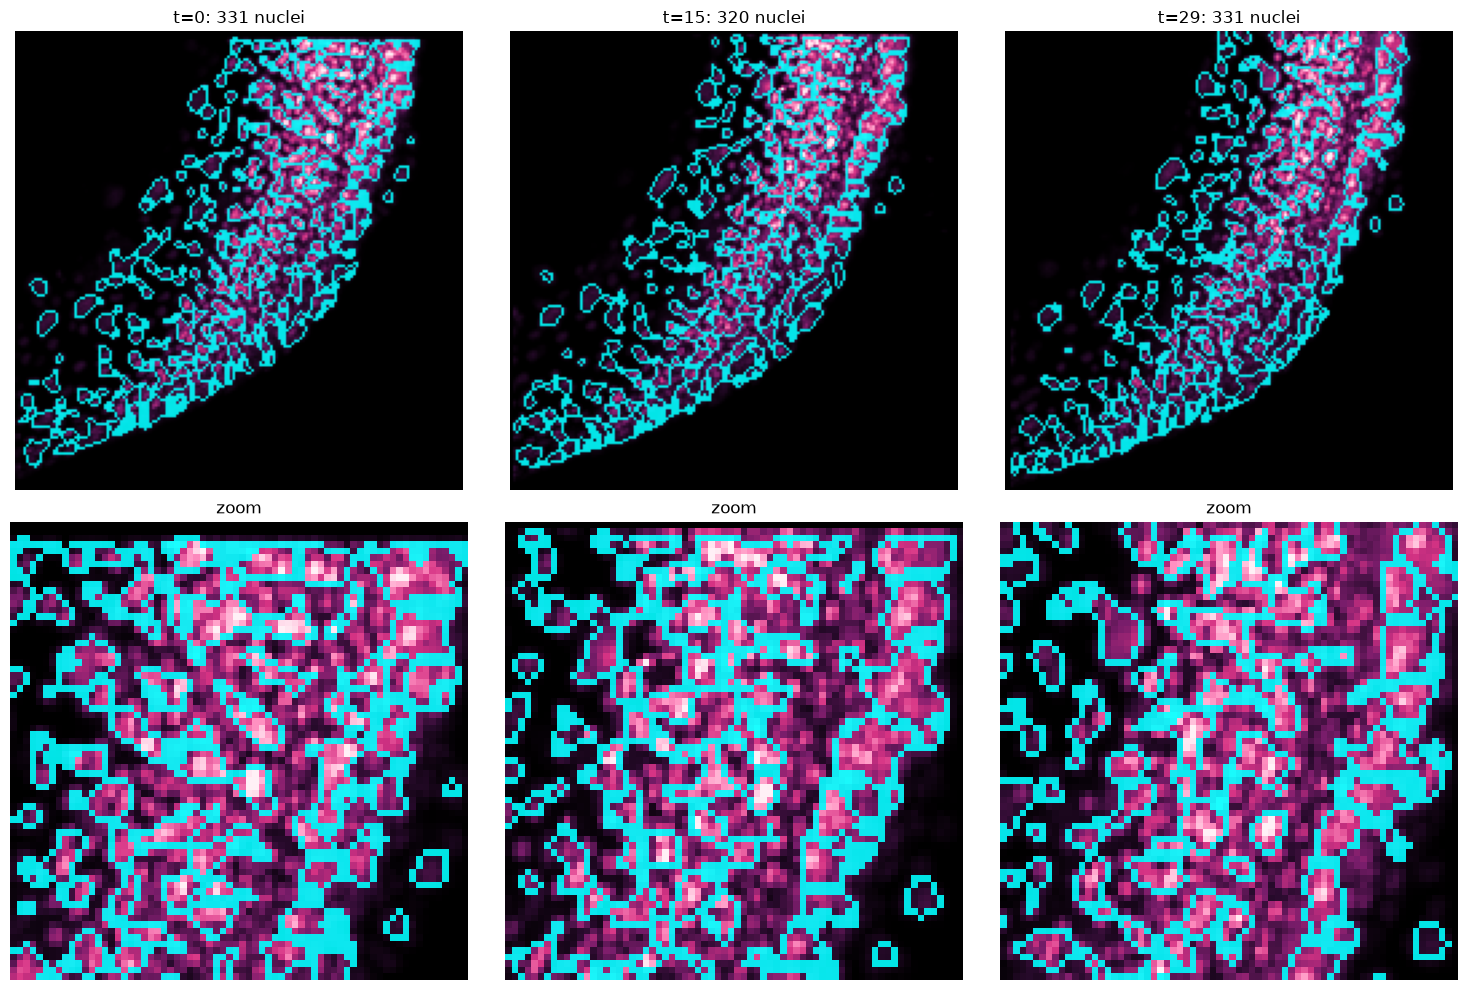

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for col, t in enumerate((0, 15, 29)):
    f_t, lab = norm[t], all_labels[t]
    edges = segmentation.find_boundaries(lab, mode="inner")
    outline = np.zeros(f_t.shape + (4,))
    outline[edges] = (0, 1, 1, 0.9)

    # top row: whole frame
    axes[0, col].imshow(f_t, cmap=pink_fluor, vmin=0, vmax=1.2)
    axes[0, col].imshow(outline)
    axes[0, col].set_title(f"t={t}: {lab.max()} nuclei")

    # bottom row: zoom on the patch
    axes[1, col].imshow(f_t[ys, xs], cmap=pink_fluor, vmin=0, vmax=1.2)
    axes[1, col].imshow(outline[ys, xs])
    axes[1, col].set_title("zoom")

    axes[0, col].axis("off"); axes[1, col].axis("off")
plt.tight_layout(); plt.show()